<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 15 · In production</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A forecasting model is fitted to a process that keeps changing: its inputs, its target's level, or the relationship between them, as when a new farm starts supplying. An early or late season is not drift but variation the model should already know. A forecaster learns of a change late: each forecast's error is known only $h$ weeks after issue, plus the data latency. On 20 synthetic weekly harvest histories in which a new farm joins in season 6, a gradient-boosted model never retrained had a mean absolute error of $18.1$ t/week that season, against $13.1$ for the same model refitted every four weeks on all its history. Favouring recent data did not help: a two-season sliding window was worse in every period, and recency weights at best tied. The expanding window was also the steadiest, moving its forecasts by $2.1$ t/week per refit. Afterwards you should be able to classify a change, estimate how long it goes unnoticed, compare retraining policies by backtest, and measure how far each refit moves the forecast.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
threadpool_limits(1)  # thousands of small fits run faster on one thread each
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
P, H = 52, 4  # weeks per season; forecast horizon in weeks
CHANGE, END = 5 * P, 7 * P  # the change arrives in week 260, the first week of season 6; seven seasons in all

## Kinds of change

A forecast goes stale in two ways: the inputs look different, or the same inputs now lead to different harvests. Write the joint distribution of the features and the target as

$$P_t(\mathbf{x}, y) = P_t(\mathbf{x})\, P_t(y \mid \mathbf{x})$$

where $\mathbf{x}$ is the feature vector known at the forecast origin, $y$ the target (here harvest, in tonnes per week, t/week), and $t$ the time at which the pair is drawn. Lu and colleagues define concept drift as any change in it over time, classified by which part changes: $P(\mathbf{x})$ alone (virtual drift), $P(y \mid \mathbf{x})$ (actual drift), or both, which they note often occur together[^1]. For a forecaster:

| Kind | What changes | Produce example | When it can be seen |
|---|---|---|---|
| **Covariate (input) drift** | $P(\mathbf{x})$ | a heat wave beyond any in the training data | at the origin, from the features |
| **Target (label) drift** | $P(y)$ | volumes rise as new plantings come into bearing | when the targets arrive |
| **Concept drift** | $P(y \mid \mathbf{x})$ | a new variety or farm; a packing line that grades out more fruit | through the errors, once targets arrive |
| **Seasonal regime** | nothing, over a run of years | an early or late season; a big or small crop | not drift |

A new farm brings the first three at once. The last row is the one most often mistaken for drift: early and late seasons are already in the history, and a model that "adapts" to one will be wrong when timing returns to normal.

## Why a forecaster sees it late

Concept drift shows only through the model's errors, and the error of a forecast $\hat{y}_{t+h \mid t}$, issued at origin $t$ for $h$ weeks ahead (the notation of [Horizon, frequency and target](../horizon-frequency-and-target.qmd)), is known only when $y_{t+h}$ arrives. Gama and colleagues treat true values that arrive with a delay, or not at all, as a variation of the learning set-up[^2]; for a forecaster the delay is built in.

Take $h = 4$ weeks, a data latency of $d = 1$ week, and a change that first affects the harvest in week 260. The forecast issued in week 256 for week 260 is the first wrong one, and its error is known in week 261. A rule that waits for $k$ bad errors before raising an alarm, so one bad week does not set it off, needs the errors for weeks 260 to 263 when $k = 4$; the last arrives in week 264, when the alarm fires. Every forecast issued from week 256 to 264 came from a model that had never seen the change: $h + d + k = 4 + 1 + 4 = 9$ weekly issues, against a season whose bulk (the peak $\pm 2$ standard deviations of $5$ weeks, below) lasts $20$ weeks.

Covariate drift is the exception: an input outside its training range can be flagged the day the forecast is issued, which says the model is extrapolating, not that it is wrong.

## Four policies, one change

A retraining policy says when to refit and on which rows:

- **Never retrain.** Fit once.
- **Fixed schedule, expanding window.** Refit every $r$ weeks on every row whose target has been observed.
- **Fixed schedule, sliding window.** The same, on the last $W$ weeks only.
- **Fixed schedule, recency-weighted.** Every row, with weight

$$w_i = 2^{-a_i / T_{1/2}}$$

where $a_i$ is the age in weeks of row $i$'s target at the refit, $T_{1/2}$ the half-life in weeks, and $w_i$ the dimensionless weight passed as `sample_weight`.

Gama and colleagues call the window *abrupt forgetting* and the weights *gradual forgetting*, and note that the more abrupt the forgetting, the faster the reaction and the higher the risk of fitting noise.

The data are **synthetic**, from fixed seeds: the series of [Backtesting properly](../backtesting/backtesting_properly.ipynb), one bell-shaped harvest a season whose height and timing vary, plus autocorrelated noise. In week 260, the start of season 6, a smaller second farm joins whose harvest peaks eight weeks before the main one.

::: {.callout-note collapse="true"}
## The generating equation

$$y_t = 5 + A_s\, g(w_t;\, m_s, 5) + \mathbb{1}[t \ge 260]\; B_s\, g(w_t;\, m_s - 8, 4) + \varepsilon_t, \qquad g(w;\, m, \sigma) = \exp\!\left(-\frac{(w - m)^2}{2\sigma^2}\right)$$

where $y_t$ is the harvest in week $t$ (t/week, set to zero if negative), $s$ the season containing week $t$, $w_t$ the week of the season ($0$ to $51$), $A_s \sim \mathcal{N}(100, 20^2)$ the main peak's height (t/week), $m_s \sim \mathcal{N}(26, 2.5^2)$ its week, $B_s \sim \mathcal{N}(60, 10^2)$ the new farm's peak height (t/week), $g$ a bell of centre $m$ and width $\sigma$ (weeks), $\mathbb{1}[\cdot]$ equal to $1$ when the condition holds and $0$ otherwise, and $\varepsilon_t = 0.7\,\varepsilon_{t-1} + \eta_t$ noise with $\eta_t \sim \mathcal{N}(0, 4^2)$ t/week.
:::

In [2]:
def simulate(seed, change="new farm"):
    """Synthetic weekly harvest (t/week), seven seasons, with a change from season 6."""
    rng = np.random.default_rng(seed)
    t = np.arange(END)
    week, s = t % P, t // P
    size = rng.normal(100, 20, 7)[s]  # A_s, peak height
    peak = rng.normal(26, 2.5, 7)[s]  # m_s, week of peak
    after = t >= CHANGE
    if change == "new farm":  # a second, earlier peak from season 6
        extra = rng.normal(60, 10, 7)[s] * np.exp(-0.5 * ((week - peak + 8) / 4) ** 2)
        y = 5 + size * np.exp(-0.5 * ((week - peak) / 5) ** 2) + after * extra
    else:  # "earlier season": from season 6 the whole season comes six weeks earlier
        y = 5 + size * np.exp(-0.5 * ((week - peak + 6 * after) / 5) ** 2)
    noise = np.zeros(END)
    for i in range(1, END):  # AR(1): a good week tends to follow a good week
        noise[i] = 0.7 * noise[i - 1] + rng.normal(0, 4)
    return pd.Series(np.clip(y + noise, 0, None))

The model is the gradient-boosted trees of the backtesting module, forecasting $h = 4$ weeks ahead. Each row is one forecast origin $t$, with features all known at $t$, the as-of rule of [Leakage](../leakage/leakage.ipynb):

- the harvest in weeks $t$, $t-1$ and $t-2$;
- the harvest in the target's week one season earlier, $y_{t+h-52}$;
- the target's week of the season, $0$ to $51$.

Every week of seasons 4 to 7 is a target. The never-retrain model is fitted once, on seasons 1 to 3; the others refit every $r = 4$ weeks on rows whose target had been observed. The sliding window is two seasons ($W = 104$ weeks), the half-life one season ($T_{1/2} = 52$ weeks).

In [3]:
FEATS = ["y_t", "y_t-1", "y_t-2", "same_week_last_season", "target_week"]
POLICIES = {
    "never retrain": dict(refit=False),
    "expanding": dict(),
    "sliding, 2 seasons": dict(window=2 * P),
    "recency-weighted": dict(half_life=P),
}

def rows(y, h=H):
    """One row per origin t: features known at t, target y[t+h]."""
    t = np.arange(len(y))
    return pd.DataFrame({
        "y_t": y, "y_t-1": y.shift(1), "y_t-2": y.shift(2),
        "same_week_last_season": y.shift(P - h),  # y[t+h-52], known at t
        "target_week": (t + h) % P, "target_time": t + h, "target": y.shift(-h),
    }).dropna()

def replay(d, refit=True, window=None, half_life=None, every=4):
    """Issue the forecasts for seasons 4-7, refitting every few weeks (or never)."""
    test = d[(d.target_time >= 3 * P) & (d.target_time < END)].assign(jump=np.nan)
    fit = None
    for _, block in test.groupby(np.arange(len(test)) // every):
        origin = block.index[0]  # origin = the week the forecast is issued
        if fit is None or refit:
            tr = d[d.target_time <= origin]  # only targets observed by the origin
            if window:
                tr = tr[tr.target_time > origin - window]
            w = None if half_life is None else 0.5 ** ((origin - tr.target_time) / half_life)
            new = HistGradientBoostingRegressor(max_iter=100, random_state=0).fit(tr[FEATS], tr.target, sample_weight=w)
            if fit is not None:  # how far this refit alone moved these forecasts
                test.loc[block.index, "jump"] = np.abs(new.predict(block[FEATS]) - fit.predict(block[FEATS]))
            fit = new
        test.loc[block.index, "pred"] = fit.predict(block[FEATS])
    return test

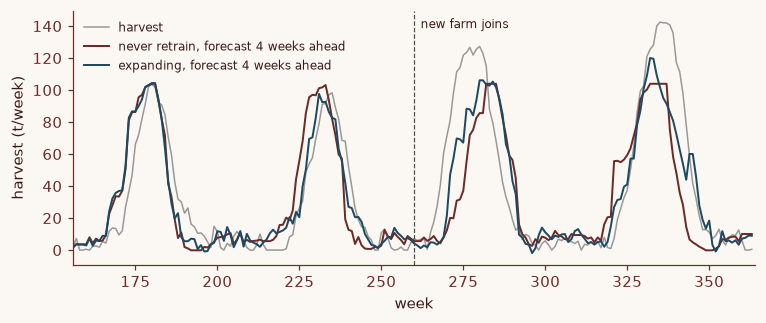

In [4]:
y = simulate(seed=0)
d = rows(y)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(np.arange(3 * P, END), y[3 * P :], color="0.6", lw=1, label="harvest")
for name, c in [("never retrain", C3), ("expanding", C1)]:
    r = replay(d, **POLICIES[name])
    ax.plot(r.target_time, r.pred, color=c, lw=1.3, label=f"{name}, forecast 4 weeks ahead")
ax.axvline(CHANGE, color="0.3", lw=0.8, ls="--")
ax.text(CHANGE + 2, 0.97, "new farm joins", transform=ax.get_xaxis_transform(), va="top", fontsize=8)
ax.set(xlabel="week", ylabel="harvest (t/week)", xlim=(3 * P, END))
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.show()

<strong>Figure 1 | A change the model learns of late.</strong> Seasons 4 to 7 of one synthetic history. From season 6 the harvest rises earlier and peaks higher. Both models forecast the season-6 rise late. In season 7 both rise earlier, because the lags carry the change, but the never-retrain model here tops out at about the height of the peaks it was trained on, as tree models do not extrapolate far beyond their training targets.

One history is one draw of weather, so the table averages 20: mean absolute error (MAE, t/week) before the change (seasons 4 and 5) and in the two seasons after it, beside seasonal naive, $\hat{y}_{t+h \mid t} = y_{t+h-52}$.

In [5]:
def period(target_time):
    return pd.cut(target_time, [0, CHANGE, 6 * P, END], right=False, labels=["seasons 4-5", "season 6", "season 7"])

def experiment(change, seeds=range(20)):
    out = []
    for seed in seeds:
        d = rows(simulate(seed, change))
        for name, kw in POLICIES.items():
            r = replay(d, **kw)
            out.append(pd.DataFrame({
                "seed": seed, "policy": name, "period": period(r.target_time),
                "jump": r.jump, "error": (r.pred - r.target).abs(),
                "naive error": (r.same_week_last_season - r.target).abs(),
            }))
    return pd.concat(out, ignore_index=True)

def mae_table(res):
    t = res.pivot_table(index="policy", columns="period", values="error", observed=True)
    t.loc["seasonal naive"] = res[res.policy == "expanding"].groupby("period", observed=True)["naive error"].mean()
    return t.loc[[*POLICIES, "seasonal naive"]]


new_farm = experiment("new farm")
mae_table(new_farm).round(1)

period,seasons 4-5,season 6,season 7
policy,,,
never retrain,12.8,18.1,14.7
expanding,12.0,13.1,10.8
"sliding, 2 seasons",12.9,14.2,14.3
recency-weighted,12.3,13.1,11.4
seasonal naive,16.3,20.5,18.6


Retraining pays after the change: in season 6 the never-retrain model's MAE is $18.1$ t/week against $13.1$ for the expanding window, $18.1/13.1 = 1.38$ times as large, and a season later $14.7$ against $10.8$. Before the change it bought little, $12.8$ against $12.0$.

Favouring recent data did not help. The sliding window was the worst retraining policy in every period, in season 7 hardly better than never retraining ($14.3$ against $14.7$). Recency weighting tied the expanding window in season 6 ($13.1$) and trailed it in season 7 ($11.4$). Counting wins per history:

In [6]:
per_history = new_farm.groupby(["period", "seed", "policy"], observed=True).error.mean().unstack()
beats = per_history.lt(per_history["expanding"], axis=0).groupby("period", observed=True).mean()
beats.drop(columns="expanding").round(2)  # share of the 20 histories with a lower MAE than expanding

policy,never retrain,recency-weighted,"sliding, 2 seasons"
period,,,
seasons 4-5,0.35,0.30,0.25
season 6,0.05,0.50,0.35
season 7,0.25,0.35,0.10


Recency weighting beat the expanding window in half the histories in season 6, a coin toss, and in $35\%$ in season 7; the sliding window in $10\%$ in season 7.

Why recency lost here is an untested hypothesis, with two candidate causes. **Fewer seasons:** these seasons differ a lot ($A_s$ varies by $20\%$ of its mean), and a two-season window learns that variation from two draws instead of up to six. **The lags already carry the change:** once season 6 is in the training data, high lags and a high same-week-last-season value arrive with high targets, whatever the window. On your own data, count the seasons a window holds, and check whether the features already describe the change. Moving the whole season six weeks earlier instead gives the same ranking:

In [7]:
mae_table(experiment("earlier season")).round(1)

period,seasons 4-5,season 6,season 7
policy,,,
never retrain,12.9,19.8,13.0
expanding,12.2,15.7,10.8
"sliding, 2 seasons",13.1,17.4,11.7
recency-weighted,12.6,15.7,10.7
seasonal naive,16.6,26.7,16.1


Never retraining again cost most ($19.8$ against $15.7$ in season 6), recency weighting tied the expanding window, and the sliding window trailed. A known change, such as a new farm with its planted area on record, need not wait for the errors: forecast the farm from its area, as in the cold-start section of [Forecasting many series at once](../many-series/forecasting_many_series.ipynb).

## The cost of refitting

**Compute.** Refitting every four weeks for four seasons is $4 \times 52 / 4 = 52$ fits per history, against one: trivial for one series, the limit on cadence for a global model over thousands of series.

**Instability.** A refit changes the forecast for a week even when nothing new is known about that week, and planners stop trusting a forecast that moves without reason. Measure it at each refit by forecasting the same rows with the outgoing and incoming models:

$$J = \frac{1}{n} \sum_{i=1}^{n} \left| \hat{y}^{\,\text{new}}_{i} - \hat{y}^{\,\text{old}}_{i} \right|$$

where $\hat{y}^{\,\text{old}}_{i}$ and $\hat{y}^{\,\text{new}}_{i}$ are the two models' forecasts (t/week) for row $i$ from the same origin and features, and $n$ the number of such rows in a period. $J$ needs no labels, so it can be checked before release.

In [8]:
jump = new_farm.pivot_table(index="policy", columns="period", values="jump", observed=True)
jump.round(1)  # mean |new forecast - old forecast| at a refit, t/week; never retrain has no refits

period,seasons 4-5,season 6,season 7
policy,,,
expanding,2.1,1.8,1.9
recency-weighted,2.6,2.6,2.6
"sliding, 2 seasons",2.5,2.7,2.7


The expanding window was the steadiest: $2.1$ t/week per refit before the change, against $2.5$ for the sliding window and $2.6$ for recency weighting, about $2.1/12.0 \approx 18\%$ of its own MAE. Nothing was changing in seasons 4 and 5, so those jumps are noise; forgetting faster gives the newest rows more say and moves the forecast more. The jumps barely changed when the change arrived, so $J$ is a release check, not a drift detector.

**Trigger-based retraining** refits only when the error over the last $k$ resolved forecasts crosses a threshold. It saves fits but inherits the $h + d + k$ weeks of delay, and on a seasonal series a fixed threshold on raw error fires at every peak, because the error grows with the harvest. Setting it is the subject of the next module, on monitoring a forecast. Until then, a simple check: compare the recent rolling error with the model's error on the same weeks last season and with seasonal naive's on these weeks, and look harder when both stay bad.

**A default to start from**, consistent with these results rather than proven by them: refit on a fixed schedule (every four weeks here) on an expanding window, log each version's forecasts so $J$ can be checked at release, and adopt a recency scheme only if a backtest on your own data shows it gains enough to pay for its extra refits and jumps. This design does not test gradual drift or short histories, such as three seasons, either of which could change the ranking.

## Key takeaways

- Separate covariate, target and concept drift from seasonal regimes, which the history should already contain.
- Concept drift shows only through errors, $h + d$ weeks late; an alarm that waits for $k$ of them leaves $h + d + k$ issues to the old model.
- Retraining on a schedule pays after a change. Favouring recent data is a hypothesis to backtest, not a default.
- Measure how far each refit moves the forecast before releasing it.

## References

[^1]: Lu, J. et al. Learning under concept drift: a review. *IEEE Trans. Knowl. Data Eng.* **31**, 2346–2363 (2019). https://doi.org/10.1109/TKDE.2018.2876857
[^2]: Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M. & Bouchachia, A. A survey on concept drift adaptation. *ACM Comput. Surv.* **46**, 1–37 (2014). https://doi.org/10.1145/2523813

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/ets-and-arima/ets_and_arima.html"><span>Previous</span>ETS and ARIMA</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/monitoring/monitoring_a_forecast.html"><span>Next</span>Monitoring a forecast</a></div>
<!-- CURRICULUM_FOOTER_END -->